# 7b. Additions: How a Computer Stores Data

Additions to [Chapter 7: Iteration and Search](https://y-rosenthal.github.io/yrThinkPython/chap07.html):
how a computer stores text, pictures and sound as numbers, and what a text file is. Chapter 7 reads the
text file `words.txt`; this page explains what is in such a file. Read this page after the chapter.
The practice questions at the end have answers: try each question first, then open its **Answer**.

[Run this page on Colab](https://colab.research.google.com/github/y-rosenthal/yrThinkPython/blob/v3/yr/chap07_additions_data.ipynb)

Run the setup cell below first. In Colab, it downloads the file `words.txt` (the word list that
Chapter 7 uses), and `thinkpython.py`, which lets this page show the errors of some examples without
stopping the page.

In [1]:
from os.path import basename, exists

def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + str(local))
    return filename

download('https://github.com/AllenDowney/ThinkPython/raw/v3/thinkpython.py');
download('https://raw.githubusercontent.com/AllenDowney/ThinkPython/v3/words.txt');

import thinkpython

## All data is stored as numbers

At the lowest level, a computer stores **only numbers**. Its memory and its disk hold numbers, and nothing
else. Every kind of data is stored as numbers:

- **text**: each character is a number (the sections "Binary numbers" and "Text: characters as numbers");
- **pictures**: each small dot of the picture is three numbers (the section "Pictures: pixels and RGB colors");
- **sound**: the loudness of the sound, measured many times each second, is a sequence of numbers (the section
  "Sound");
- **video**: a sequence of pictures, and the sound;
- **programs**: the instructions of a program are numbers too.

A program gives the numbers their meaning. The same numbers can be letters in one program and colors in
another. For example, in a text file the number 65 is the letter `A`, and in a picture it can be the brightness of
the red part of the color of a dot.

The computer stores each number as a **binary number**: a number that has only the digits 0 and 1. The
hardware of a computer can store and change two states very fast. For example, a part of a memory chip holds
an electric charge or no charge, and a spot on a hard disk is magnetized in one direction or the other. One
state is 0 and the other state is 1.

- A **bit** (from *binary digit*) is one 0 or 1.
- A **byte** is 8 bits, for example `01000001`. Sizes of files and memory are given in bytes: a kilobyte (KB)
  is about one thousand bytes, a megabyte (MB) about one million, and a gigabyte (GB) about one billion.

## Binary numbers

**Decimal numbers.** The numbers that people use every day are *decimal* numbers: they have the 10 digits
0 to 9. Each position of a digit has a *place value*. From the right, the place values are 1, 10, 100, 1000,
and so on: each place value is 10 times the place value at its right. The number 4072 means:

| Place value | 1000 | 100 | 10 | 1 |
|---|---|---|---|---|
| Digit | 4 | 0 | 7 | 2 |

4072 = 4×1000 + 0×100 + 7×10 + 2×1.

**Binary numbers.** A binary number has only the 2 digits 0 and 1. From the right, its place values are
1, 2, 4, 8, 16, 32, 64, 128, and so on: each place value is **2 times** the place value at its right.

**Convert a binary number to a decimal number.** Write the place value above each digit. Then add the place
values of the digits that are 1, and ignore the digits that are 0. For example, the binary number `1011`:

| Place value | 8 | 4 | 2 | 1 |
|---|---|---|---|---|
| Digit | 1 | 0 | 1 | 1 |

`1011` = 8 + 2 + 1 = **11**.

Another example, the byte `01000001`:

| Place value | 128 | 64 | 32 | 16 | 8 | 4 | 2 | 1 |
|---|---|---|---|---|---|---|---|---|
| Digit | 0 | 1 | 0 | 0 | 0 | 0 | 0 | 1 |

`01000001` = 64 + 1 = **65**. Zeros at the left do not change the value, the same as in a decimal number
(`0042` is 42).

The largest number in one byte is `11111111` = 128 + 64 + 32 + 16 + 8 + 4 + 2 + 1 = **255**. So one byte
holds a number from 0 to 255: 256 different values.

**Convert in Python.** `int(TEXT, 2)` converts a string of binary digits to a number. The second argument, 2,
tells `int` that the digits are binary digits. (`int(TEXT)` without a second argument reads decimal digits.)

In [2]:
int('1011', 2)

11

In [3]:
int('01000001', 2)

65

In [4]:
int('11111111', 2)

255

A binary number can have only the digits 0 and 1. With any other digit, `int` raises a `ValueError`:

In [5]:
int('1021', 2)

ValueError: invalid literal for int() with base 2: '1021'

## Text: characters as numbers

A computer stores each character of a text as a number. A **character encoding** is a table that gives
the number of each character. A program that stores text uses the table to change each character into its
number. A program that shows text uses the table to change each number back into its character.

### ASCII

**ASCII** (American Standard Code for Information Interchange, from 1963) is the oldest character encoding
that is still in use. It gives numbers to 128 characters, with the numbers 0 to 127:

| Characters | Numbers |
|---|---|
| the uppercase letters `A` to `Z` | 65 to 90 (`A` is 65, `B` is 66, ... `Z` is 90) |
| the lowercase letters `a` to `z` | 97 to 122 (`a` is 97, `b` is 98, ... `z` is 122) |
| the digits `0` to `9` | 48 to 57 (`0` is 48, `1` is 49, ... `9` is 57) |
| the space | 32 |
| punctuation and symbols, such as `!`, `,`, `.`, `?`, `+`, `@` | numbers between 33 and 126 |
| control characters, such as the newline `\n` (10), the carriage return `\r` (13) and the tab `\t` (9) | 0 to 31, and 127 |

The control characters are not shown as symbols. They tell a program what to do: for example, the newline
character tells a program that shows the text to start a new line.

The ASCII characters are only the characters of English: the table has no `é`, no `ñ`, no Hebrew or Chinese
letters, and no emoji.

### `ord` and `chr`

The built-in function `ord(CHARACTER)` returns the number of a character. For the ASCII characters, this is
the ASCII number:

In [6]:
ord('A')

65

In [7]:
ord('a')

97

The built-in function `chr(NUMBER)` does the opposite: it returns the character of a number.

In [8]:
chr(66)

'B'

This loop shows the number of each character of a string. The space and the `!` are characters too, so
they have numbers:

In [9]:
for letter in 'Hi there!':
    print(letter, ord(letter))

H 72
i 105
  32
t 116
h 104
e 101
r 114
e 101
! 33


**The digit characters are not their values.** The character `'7'` is stored as the number 55, not as the
number 7. `int` converts the text `'7'` to the number 7:

In [10]:
print(ord('7'))
print(int('7'))

55
7


**`ord` takes one character.** With a string of two or more characters, `ord` raises a `TypeError`:

In [11]:
ord('Hi')

TypeError: ord() expected a character, but string of length 2 found

**From bits to characters.** In the computer, the text `Hi` is the two bytes `01001000` and `01101001`. To
read the text, convert each byte to a number, then find the character of the number:

In [12]:
print(int('01001000', 2), chr(int('01001000', 2)))
print(int('01101001', 2), chr(int('01101001', 2)))

72 H
105 i


### Other encodings: Unicode and UTF-8

ASCII is not the only character encoding. Other encodings give numbers to other characters, and different
encodings can give **different numbers to the same character**. Some examples:

- **Unicode** is a standard that gives a number to almost every character of every written language, and to
  emoji: more than 150,000 characters. Python strings are Unicode strings: `'café'`, `'שלום'` and `'😀'` are
  all strings.
- **UTF-8** is the most common way to store Unicode text in a file or send it on the internet. Most web
  pages, and most text files made today, are UTF-8. UTF-8 uses the same numbers as ASCII for the 128 ASCII
  characters, so a file that has only ASCII characters is also a UTF-8 file. For all the other characters,
  such as `é`, UTF-8 uses different numbers, and it stores many characters in two, three or four bytes, not in
  one.
- **UTF-16** is another way to store Unicode. It stores each character, also `A`, in two or four bytes, so
  even an English text is stored with different bytes than in ASCII.
- **Older encodings**, such as Latin-1 (for Western European languages), Windows-1252, and Shift JIS (for
  Japanese), give their own numbers to the characters of one language or group of languages.

**A file does not say which encoding it uses.** A program that reads a text file must use the same encoding as
the program that wrote it. If it uses another encoding, it shows the wrong characters. For example, a UTF-8
file that has the word `café` can be shown as `cafÃ©` by a program that reads it as Windows-1252: the bytes of
`é` in UTF-8 are the numbers of two other characters in Windows-1252.

:::{admonition} Diving deeper: give the encoding to open
:class: dropdown

`open` uses a default encoding to change the numbers of a file into characters. On a Mac, on Linux and in
Colab, the default is UTF-8. On Windows, the default can be another encoding (for example Windows-1252), so a
UTF-8 file with characters such as `é` can show the wrong characters, or `open` can raise a
`UnicodeDecodeError`. To read a UTF-8 file in the same way on every computer, give the encoding to `open`:

```python
for line in open('words.txt', encoding='utf-8'):
    print(line.strip())
```

`encoding='utf-8'` is a *keyword argument*, as `end=' '` in `print(letter, end=' ')`.
:::


## Text files and binary files

Every file on a disk is a sequence of bytes: numbers from 0 to 255. Files are of two kinds, by what these
numbers mean.

**A plain text file** (also called a **text file**, or a **flat file**) is a file whose bytes are only the
numbers of characters, in one character encoding: letters, digits, punctuation, spaces, tabs and newlines.
Each line of the text ends with a newline character. (Many files made on Windows end each line with two
characters: a carriage return and a newline.) A text file has no fonts, no bold text, no pictures: only
characters.

- Any text editor shows the characters of a text file: Notepad (Windows), TextEdit (Mac), VS Code.
- Examples: `.txt` files, Python programs (`.py`), CSV files (`.csv`), web pages (`.html`).
- `words.txt` is a text file, with one word on each line (the end of this section shows its bytes).
- People use the name *flat file* most for a text file that holds data, one record on each line, for example
  one word on each line (`words.txt`) or one row of a table on each line (a CSV file).

**A binary file** is any other file. Its bytes are numbers that are not characters: the numbers of the
pixels of a picture, of the samples of a sound, or of a format that only one kind of program can read.

- Examples: pictures (`.jpg`, `.png`), sound (`.mp3`, `.wav`), video (`.mp4`), Word documents (`.docx`),
  Excel files (`.xlsx`), PDF files (`.pdf`), programs (`.exe`), zip files (`.zip`).
- A text editor shows a binary file as random symbols, because it changes each number into a character, and
  the numbers are not characters. To use a binary file, you need a program that knows its format: a photo
  viewer, a music player, Word.

A Word document is not a text file, though it holds text: it also holds the fonts, the layout and the
pictures, in a binary format.

**See the numbers in a file.** In Python, `open(PATH, 'rb')` opens a file in *binary mode* (`'rb'`: read
binary). Then the method `read(N)` returns the first `N` bytes of the file, and a `for` loop on them gives
each byte as a number. These are the first 9 bytes of `words.txt`:

In [13]:
file_object = open('words.txt', 'rb')
for number in file_object.read(9):
    print(number, chr(number))

97 a
97 a
13 
10 

97 a
97 a
104 h
13 
10 



The first lines of `words.txt` are `aa` and `aah`. The bytes are the ASCII numbers of their characters: 97 is
`a` and 104 is `h`. Each line ends with two control characters, 13 (the carriage return `\r`) and 10 (the
newline `\n`), because the file was made in the Windows way. These two characters are not shown as symbols:
`print` shows an empty line for the newline. Without `'rb'`, `open` changes the numbers into characters for
you, and it changes each carriage return and newline at the end of a line into one `\n`. That is why
`readline` in Chapter 7 returns `'aa\n'`.

## Pictures: pixels and RGB colors

**Pixels.** A picture on a screen is a grid of very small squares of color, called **pixels** (from
*picture element*). Each pixel has one color. The pixels are so small that you do not see them one by one:
you see the picture. For example:

- a computer screen of 1920 × 1080 pixels has 1920 columns and 1080 rows of pixels: 2,073,600 pixels;
- a photo of 12 megapixels (from a phone camera) has about 12 million pixels.

**RGB colors.** A screen makes the color of each pixel with three small lights: a **r**ed one, a **g**reen
one and a **b**lue one. So the computer stores the color of a pixel as **three numbers**: how bright the red
light is, how bright the green light is, and how bright the blue light is. Each number is from 0 (off) to
255 (as bright as possible): one byte. These three numbers are the **RGB** value of the color.

| RGB value | Color |
|---|---|
| (255, 0, 0) | red |
| (0, 255, 0) | green |
| (0, 0, 255) | blue |
| (255, 255, 0) | yellow (red and green light together) |
| (0, 0, 0) | black (all three lights off) |
| (255, 255, 255) | white (all three lights as bright as possible) |
| (128, 128, 128) | gray |

Each of the three numbers has 256 values, so there are 256 × 256 × 256 different colors:

In [14]:
256 * 256 * 256

16777216

**A picture is a sequence of numbers.** The computer stores a picture as the RGB values of its pixels, row by
row: three numbers for the first pixel of the first row, then three numbers for the next pixel, and so on. This
very small picture has 2 rows of 3 pixels: 6 pixels, so 18 numbers. Each pixel shows its RGB value:

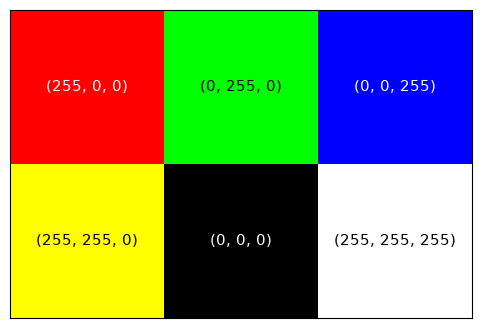

In [15]:
# @title A picture of 2 rows and 3 pixels
import matplotlib.pyplot as plt

rows = [[(255, 0, 0), (0, 255, 0), (0, 0, 255)],
        [(255, 255, 0), (0, 0, 0), (255, 255, 255)]]

fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow([[[n / 255 for n in rgb] for rgb in row] for row in rows])
for r, row in enumerate(rows):
    for c, rgb in enumerate(row):
        color = 'black' if 0.3 * rgb[0] + 0.6 * rgb[1] + 0.1 * rgb[2] > 128 else 'white'
        ax.text(c, r, str(rgb), ha='center', va='center', color=color, fontsize=11)
ax.set_xticks([])
ax.set_yticks([])
plt.show()

The numbers of this picture, row by row, are:

```
255 0 0   0 255 0   0 0 255   255 255 0   0 0 0   255 255 255
```

and the computer stores each of these numbers as a byte, in binary: 255 is `11111111`, and 0 is `00000000`.

A picture with more pixels has more numbers. A photo of 12 million pixels has 36 million numbers (3 for each
pixel): 36 million bytes, about 36 MB. Picture files such as `.jpg` and `.png` use less space: they
*compress* the numbers, that is, they store them in a shorter form. A program that shows the picture changes
the file back into the three numbers of each pixel.

## Sound

A sound is a fast vibration of the air: the air pressure goes up and down very quickly. A microphone changes
the air pressure into an electric signal. To store the sound, the computer **measures** this signal many
times each second, and stores each measurement as a number. Each measurement is a **sample**. The picture
shows a short part of a sound: the line is the sound, and each dot is one sample.

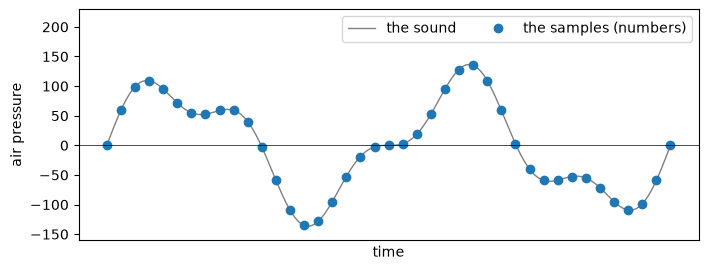

The first samples: [0, 59, 99, 109, 95, 72, 55, 53, 59, 59]


In [16]:
# @title A sound and its samples
import math
import matplotlib.pyplot as plt

times = [t / 400 for t in range(401)]
wave = [math.sin(2 * math.pi * 2 * t) + 0.4 * math.sin(2 * math.pi * 5 * t) for t in times]
sample_times = [t / 40 for t in range(41)]
samples = [round(100 * (math.sin(2 * math.pi * 2 * t) + 0.4 * math.sin(2 * math.pi * 5 * t)))
           for t in sample_times]

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(times, [100 * w for w in wave], color='gray', linewidth=1, label='the sound')
ax.plot(sample_times, samples, 'o', color='tab:blue', label='the samples (numbers)')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_xlabel('time')
ax.set_ylabel('air pressure')
ax.set_xticks([])
ax.set_ylim(-160, 230)
ax.legend(loc='upper right', ncol=2)
plt.show()
print('The first samples:', samples[:10])

So a sound is stored as a long sequence of numbers. For example, the sound on a music CD has 44,100 samples
each second for each of the two speakers (left and right), and each sample is a number from -32768 to 32767
(two bytes). To play the sound, the computer sends the numbers to the speaker, and the speaker moves the air
in the same way. Sound files such as `.mp3` compress the numbers, as `.jpg` files compress pictures.

## Summary

- A computer stores all data as numbers, and it stores each number as a binary number: a sequence of bits
  (0 or 1). A byte is 8 bits, a number from 0 to 255.
- To convert a binary number to decimal, add the place values (1, 2, 4, 8, 16, ...) of the digits that are
  1. In Python: `int(TEXT, 2)`.
- Text: a character encoding gives a number to each character. ASCII gives the numbers 0 to 127 to the
  characters of English. Other encodings (Unicode with UTF-8 or UTF-16, Latin-1, ...) give numbers to more
  characters, and can use different numbers. `ord` and `chr` change a character to its number and back.
- A plain text file holds only the numbers of characters; any text editor shows it. A binary file holds
  other numbers (pictures, sound, documents, programs), and needs a program that knows its format.
- Pictures: a grid of pixels, with three numbers (red, green, blue: each 0 to 255) for each pixel.
- Sound: samples of the sound, many each second, each a number.

## Practice questions

### Question 1 (very easy): binary to decimal

Convert the binary number `1101` to a decimal number, by hand.

:::{admonition} Answer
:class: dropdown

| Place value | 8 | 4 | 2 | 1 |
|---|---|---|---|---|
| Digit | 1 | 1 | 0 | 1 |

`1101` = 8 + 4 + 1 = **13**. To check in Python: `int('1101', 2)` returns `13`.
:::


### Question 2 (easy): a byte of text

A text file in ASCII has the byte `01100010`. Convert it to a decimal number by hand. Which character is it?
Use the ASCII table on this page.

:::{admonition} Answer
:class: dropdown

| Place value | 128 | 64 | 32 | 16 | 8 | 4 | 2 | 1 |
|---|---|---|---|---|---|---|---|---|
| Digit | 0 | 1 | 1 | 0 | 0 | 0 | 1 | 0 |

`01100010` = 64 + 32 + 2 = **98**. The lowercase letters start at 97 (`a`), so 98 is **`b`**. To check in
Python: `chr(int('01100010', 2))` returns `'b'`.
:::


### Question 3 (easy): what is displayed?

Predict what this code displays. Then run the cell to check (on the website, click **Show code cell output**).

In [17]:
for ch in 'Cab':
    print(ord(ch))

67
97
98


:::{admonition} Answer
:class: dropdown

```
67
97
98
```

The uppercase `C` is 65 + 2 = 67 (`A` is 65, `B` is 66). The lowercase `a` is 97 and `b` is 98. An uppercase
letter and its lowercase letter have different numbers.
:::


### Question 4 (easy): text file or binary file?

Which of these files are plain text files, and which are binary files?

`notes.txt`, `vacation.jpg`, `hello.py`, `song.mp3`, `grades.csv`, `essay.docx`

:::{admonition} Answer
:class: dropdown

- **Text files:** `notes.txt`, `hello.py` (a Python program is text) and `grades.csv` (a CSV file is text,
  one row of the table on each line). A text editor shows their characters.
- **Binary files:** `vacation.jpg` (a picture), `song.mp3` (sound) and `essay.docx` (a Word document: it
  holds text, but also fonts and layout, in a binary format).
:::


### Question 5 (medium): what is displayed?

Predict what this code displays. Then run the cell to check (on the website, click **Show code cell output**).

In [18]:
print(ord('7'), int('7'))
print(chr(ord('A') + 25))

55 7
Z


:::{admonition} Answer
:class: dropdown

```
55 7
Z
```

The character `'7'` is stored as the number 55 (the digits `0` to `9` are 48 to 57), and `int('7')` converts
the text to the number 7. In the second line, `ord('A') + 25` is 65 + 25 = 90, and `chr(90)` is `'Z'`: the
letters have numbers in alphabetical order.
:::


### Question 6 (medium): pixels

1. Which color has the RGB value (0, 0, 0)? Which color has the RGB value (255, 255, 255)?
2. A picture has 100 columns and 50 rows of pixels. The computer stores it without compression, with one byte
   for each number. How many bytes does the picture use?

:::{admonition} Answer
:class: dropdown

1. (0, 0, 0) is **black**: all three lights are off. (255, 255, 255) is **white**: all three lights are as
   bright as possible.
2. The picture has 100 × 50 = 5,000 pixels. Each pixel has 3 numbers (red, green, blue), and each number is
   one byte: 5,000 × 3 = **15,000 bytes**.
:::


### Question 7 (medium): wrong characters

Alice saves a text file with the word `café` in UTF-8. Bob opens the file on his computer, and his program
shows `cafÃ©`. The letters `c`, `a` and `f` are correct. Why is the `é` wrong, and why are the other letters
correct?

:::{admonition} Answer
:class: dropdown

Bob's program reads the file with a different character encoding than the one that Alice's program used to
write it (for example Windows-1252, not UTF-8). The two encodings give different numbers to `é`, so Bob's
program changes the bytes of `é` into other characters. The letters `c`, `a` and `f` are ASCII characters,
and both encodings use the ASCII numbers for them, so they are correct. To fix the problem, Bob must open the
file as UTF-8 (in Python: `open(PATH, encoding='utf-8')`).
:::


### Question 8 (hard): write a function

Write a function called `is_ascii` that takes a string and returns `True` if every character of the string is
an ASCII character (its number is less than 128), and `False` otherwise. For example, `is_ascii('hello')`
returns `True`, and `is_ascii('café')` returns `False`. An empty string has no characters that are not ASCII,
so `is_ascii('')` returns `True`.

Start from this header (replace `...` with the body):

```python
def is_ascii(text):
    ...
```

:::{admonition} Answer
:class: dropdown

```python
def is_ascii(text):
    for letter in text:
        if ord(letter) >= 128:
            return False
    return True
```

The loop checks each character. When it finds a character that is not ASCII, the function returns `False`
at once: one such character is enough. If the loop ends, no character was larger than 127, so the function
returns `True`. This is the same form as `uses_any` in Chapter 7, with `True` and `False` the other way around. For an
empty string, the loop runs zero
times, and the function returns `True`.
:::


### Question 9 (hard): write a function

Write a function called `binary_to_decimal` that takes a string of binary digits and returns its value as a
number. Do not use `int(TEXT, 2)`: use a `for` loop. For example, `binary_to_decimal('1011')` returns `11`,
`binary_to_decimal('01000001')` returns `65`, and `binary_to_decimal('11111111')` returns `255`.

Hint: start with the total 0, and go through the digits from the left. For each digit, multiply the total by
2, then add the digit (0 or 1). Multiplying by 2 moves the digits that you read before one place to the left,
as multiplying by 10 does with decimal digits (42 × 10 = 420).

Start from this header (replace `...` with the body):

```python
def binary_to_decimal(text):
    ...
```

:::{admonition} Answer
:class: dropdown

```python
def binary_to_decimal(text):
    total = 0
    for digit in text:
        total = total * 2 + int(digit)
    return total
```

For `'1011'`: 0×2 + 1 = 1, then 1×2 + 0 = 2, then 2×2 + 1 = 5, then 5×2 + 1 = 11.

Another solution uses the place values, as the section "Binary numbers" does. It goes through the digits from
the right with `reversed` (the page "7c. Additions: File Paths and for Loops" explains it), and it adds the
place value of each digit that is `'1'`. The place value starts at 1, and doubles for each digit:

```python
def binary_to_decimal(text):
    total = 0
    place_value = 1
    for digit in reversed(text):
        if digit == '1':
            total += place_value
        place_value *= 2
    return total
```

For `'1011'`, the loop sees the digits `1`, `1`, `0`, `1` (from the right), with the place values 1, 2, 4, 8:
1 + 2 + 8 = 11.
:::


## Credits

*Additions by Prof. Y. Rosenthal, for* [Think Python: 3rd Edition](https://allendowney.github.io/ThinkPython/index.html) *by Allen B. Downey.*
*Text license:* [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International](https://creativecommons.org/licenses/by-nc-sa/4.0/)